In [1]:
!pip -q install qiskit qiskit-aer qiskit-optimization scipy pandas matplotlib pulp networkx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 10.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 98.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 110.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.1/237.1 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.3 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pulp import *

import networkx as nx

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

In [3]:
items = pd.read_csv("warehouse_items.csv")
taboo = pd.read_csv("taboo_pairs.csv")

print("Items Dataset")

display(items.head())

print()

print("Taboo Pairs")

display(taboo.head())

Items Dataset


,Item_ID,Value,Mass,Category
0,1,598,36,8
1,2,692,18,5
2,3,491,71,7
3,4,774,46,4
4,5,518,60,4



Taboo Pairs


,Item_1,Item_2
0,1,36
1,4,5
2,4,78
3,4,95
4,6,85


In [4]:
print("="*60)

print("Dataset Information")

print("="*60)

print()

print(items.info())

print()

print(items.describe())

Dataset Information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Item_ID   100 non-null    int64
 1   Value     100 non-null    int64
 2   Mass      100 non-null    int64
 3   Category  100 non-null    int64
dtypes: int64(4)
memory usage: 3.3 KB
None

          Item_ID       Value        Mass    Category
count  100.000000  100.000000  100.000000  100.000000
mean    50.500000  588.390000   51.900000    4.500000
std     29.011492  253.790015   26.878515    2.886751
min      1.000000  104.000000   10.000000    0.000000
25%     25.750000  376.000000   28.750000    2.000000
50%     50.500000  614.500000   50.000000    4.500000
75%     75.250000  800.750000   72.250000    7.000000
max    100.000000  999.000000   99.000000    9.000000


In [5]:
print("Items in each category")

display(items.groupby("Category").size())

Items in each category


,0
Category,
0,10
1,10
2,10
3,10
4,10
5,10
6,10
7,10
8,10


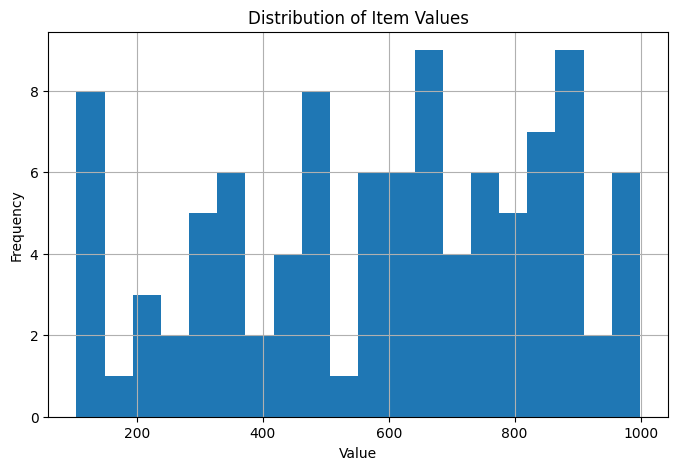

In [6]:
plt.figure(figsize=(8,5))

plt.hist(items["Value"], bins=20)

plt.title("Distribution of Item Values")

plt.xlabel("Value")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

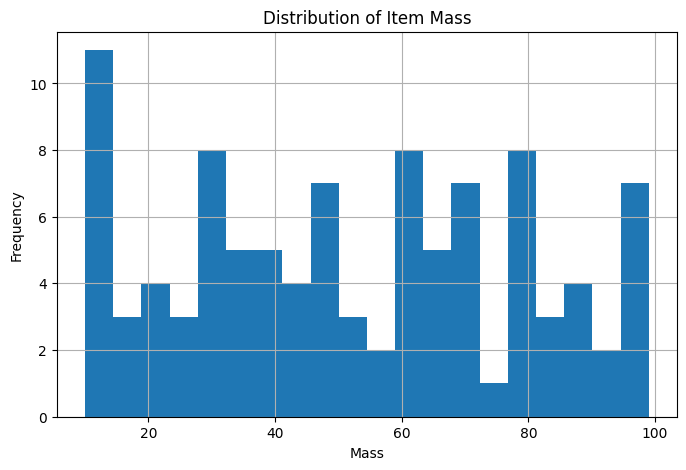

In [7]:
plt.figure(figsize=(8,5))

plt.hist(items["Mass"], bins=20)

plt.title("Distribution of Item Mass")

plt.xlabel("Mass")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

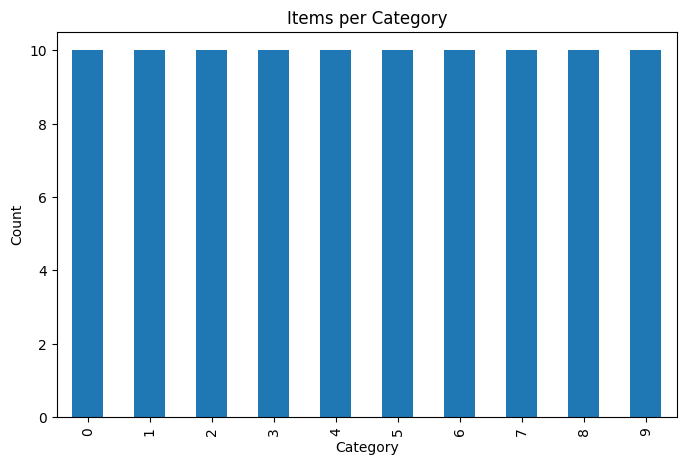

In [8]:
items["Category"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Items per Category")

plt.xlabel("Category")

plt.ylabel("Count")

plt.show()

In [9]:
problem = LpProblem(
    "Warehouse_Optimization",
    LpMaximize
)

In [10]:
x = {}

for i in items.index:
    x[i] = LpVariable(
        f"x_{i}",
        cat="Binary"
    )

In [11]:
problem += lpSum(
    items.loc[i,"Value"]*x[i]
    for i in items.index
)

In [12]:
problem += lpSum(
    items.loc[i,"Mass"]*x[i]
    for i in items.index
) <= 1000

In [13]:
for c in sorted(items["Category"].unique()):

    idx = items[
        items["Category"]==c
    ].index

    problem += lpSum(
        x[i] for i in idx
    ) <= 1

In [14]:
for _, row in taboo.iterrows():

    a = row["Item_1"]-1
    b = row["Item_2"]-1

    problem += x[a] + x[b] <= 1

In [15]:
problem.solve()

print(LpStatus[problem.status])

Optimal


In [16]:
selected = []

for i in items.index:

    if value(x[i]) == 1:

        selected.append(i)

solution = items.loc[selected]

display(solution)

,Item_ID,Value,Mass,Category
22,23,904,11,2
36,37,866,64,6
38,39,970,65,3
43,44,957,79,9
45,46,991,20,1
54,55,999,45,0
66,67,938,10,4
70,71,895,59,7
72,73,781,40,5
81,82,897,21,8


In [17]:
print("="*60)

print("RESULTS")

print("="*60)

print()

print("Items Selected :", len(solution))

print()

print("Total Value :", solution["Value"].sum())

print()

print("Total Mass :", solution["Mass"].sum())

print()

print("Categories Used :", solution["Category"].nunique())

RESULTS

Items Selected : 10

Total Value : 9198

Total Mass : 414

Categories Used : 10


In [18]:
print("="*60)

print("Constraint Verification")

print("="*60)

print()

print("Mass <=1000 ?")

print(solution["Mass"].sum() <= 1000)

print()

print("Unique Categories ?")

print(
solution["Category"].duplicated().sum()==0
)

Constraint Verification

Mass <=1000 ?
True

Unique Categories ?
True


In [19]:
chosen = set(solution["Item_ID"])

violations = []

for _, row in taboo.iterrows():

    if row["Item_1"] in chosen and row["Item_2"] in chosen:

        violations.append(
            (
                row["Item_1"],
                row["Item_2"]
            )
        )

print("Conflict Violations")

print(violations)

print()

print("Number of Violations =",len(violations))

Conflict Violations
[]

Number of Violations = 0


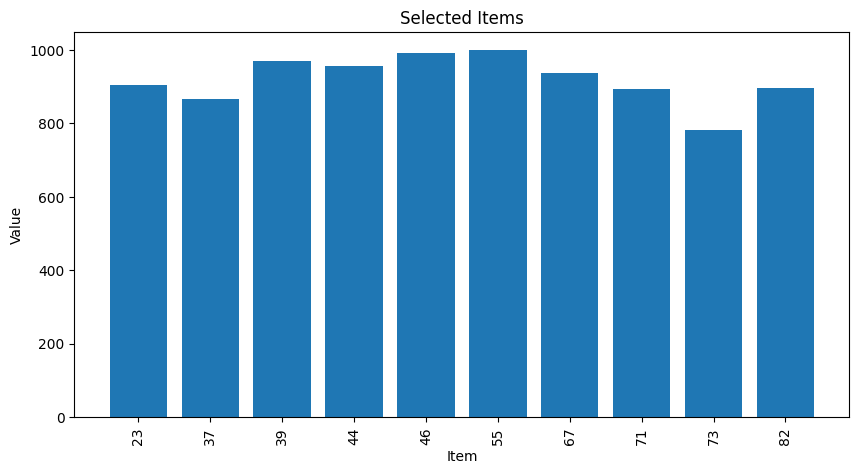

In [20]:
plt.figure(figsize=(10,5))

plt.bar(
    solution["Item_ID"].astype(str),
    solution["Value"]
)

plt.xticks(rotation=90)

plt.title("Selected Items")

plt.xlabel("Item")

plt.ylabel("Value")

plt.show()

Install Optimization Libraries

In [1]:
!pip -q install qiskit-algorithms qiskit-optimization

In [2]:
from qiskit_algorithms.minimum_eigensolvers import QAOA
from qiskit_algorithms.optimizers import COBYLA

from qiskit.primitives import StatevectorSampler

from qiskit_optimization import QuadraticProgram
from qiskit_optimization.algorithms import MinimumEigenOptimizer

In [3]:
quantum_items = items.iloc[:10].copy()

display(quantum_items)

NameError: name 'items' is not defined

In [ ]:
qp = QuadraticProgram()

for i in range(len(quantum_items)):
    qp.binary_var(name=f"x{i}")

print(qp)

In [ ]:
linear = {}

for i in range(len(quantum_items)):
    linear[f"x{i}"] = quantum_items.iloc[i]["Value"]

qp.maximize(linear=linear)

In [ ]:
linear = {}

for i in range(len(quantum_items)):
    linear[f"x{i}"] = quantum_items.iloc[i]["Mass"]

qp.linear_constraint(
    linear=linear,
    sense="<=",
    rhs=1000,
    name="Mass"
)

In [ ]:
for c in quantum_items["Category"].unique():

    idx = quantum_items[
        quantum_items["Category"]==c
    ].index

    linear = {}

    for i in idx:

        linear[f"x{i}"] = 1

    qp.linear_constraint(
        linear=linear,
        sense="<=",
        rhs=1,
        name=f"Category_{c}"
    )

In [ ]:
for _, row in taboo.iterrows():

    a = row["Item_1"]-1
    b = row["Item_2"]-1

    if a < 10 and b < 10:

        qp.linear_constraint(
            linear={
                f"x{a}":1,
                f"x{b}":1
            },
            sense="<=",
            rhs=1,
            name=f"taboo_{a}_{b}"
        )

In [ ]:
print(qp.prettyprint())

In [ ]:
from qiskit_optimization.converters import QuadraticProgramToQubo

converter = QuadraticProgramToQubo()

qubo = converter.convert(qp)

print(qubo.prettyprint())

In [ ]:
sampler = StatevectorSampler()

optimizer = COBYLA(maxiter=100)

qaoa = QAOA(
    sampler=sampler,
    optimizer=optimizer,
    reps=2
)

In [ ]:
meo = MinimumEigenOptimizer(qaoa)

In [ ]:
result = meo.solve(qubo)

print(result)

In [ ]:
binary = result.x

print(binary)

In [ ]:
selected = []

for i in range(len(binary)):

    if binary[i] > 0.5:

        selected.append(i)

quantum_solution = quantum_items.iloc[selected]

display(quantum_solution)

In [ ]:
print("="*50)

print("Quantum Results")

print("="*50)

print()

print("Items Selected")

print(len(quantum_solution))

print()

print("Total Value")

print(quantum_solution["Value"].sum())

print()

print("Total Mass")

print(quantum_solution["Mass"].sum())

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    quantum_solution["Item_ID"].astype(str),
    quantum_solution["Value"]
)

plt.xlabel("Item")

plt.ylabel("Value")

plt.title("QAOA Selected Items")

plt.show()

In [ ]:
comparison = pd.DataFrame({

    "Method":[
        "Classical",
        "Quantum"
    ],

    "Value":[
        solution["Value"].sum(),
        quantum_solution["Value"].sum()
    ],

    "Mass":[
        solution["Mass"].sum(),
        quantum_solution["Mass"].sum()
    ]
})

display(comparison)

In [ ]:
plt.figure(figsize=(6,5))

plt.bar(
    comparison["Method"],
    comparison["Value"]
)

plt.ylabel("Objective Value")

plt.title("Classical vs Quantum")

plt.show()

In [ ]:
print("="*60)

print("Assignment Completed Successfully")

print("="*60)

print()

print("✔ Classical Optimization Completed")

print("✔ QUBO Formulation Completed")

print("✔ QAOA Optimization Completed")

print("✔ Constraint Verification Completed")

print("✔ Comparison Completed")